# 02 · TF-IDF y regresión logística


1. Preprocesado del texto (como en el notebook *Text_Vectorization_I* de clase).
2. Representación **TF-IDF**.
3. **Regresión logística** (scikit-learn), con los hiperparámetros elegidos con validación.
4. Repetición con nivel 1 y palabras más importantes de cada clase.

La configuración de TF-IDF que salga aquí es la que se usa para la red en PyTorch.

## 0. Preparación

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score

if os.path.exists("/content"):          # Colab
    RUTA_DATOS = "/content/"
    RUTA_RESULTADOS = "/content/"
    RUTA_FIGURAS = "/content/"
else:                                    # local
    RUTA_DATOS = "../data/"
    RUTA_RESULTADOS = "../resultados/"
    RUTA_FIGURAS = "../figuras/"

In [2]:
datos = pd.read_pickle(RUTA_DATOS + "proyectos_etiquetados.pkl")
particion = pd.read_csv(RUTA_RESULTADOS + "particion.csv")
datos = datos.merge(particion, on="projectID")

train = datos[datos["conjunto"] == "train"].sort_values("projectID").reset_index(drop=True)
val = datos[datos["conjunto"] == "val"].sort_values("projectID").reset_index(drop=True)
test = datos[datos["conjunto"] == "test"].sort_values("projectID").reset_index(drop=True)
print(len(train), len(val), len(test))   # 22386 4798 4798

22386 4798 4798


In [3]:
def guardar_predicciones(df, y_pred, modelo, nivel, conjunto):
    """Guarda las predicciones con el formato común del equipo (lo lee el notebook 05)."""
    pd.DataFrame({"projectID": df["projectID"], "y_true": df[nivel], "y_pred": y_pred}) \
      .to_csv(RUTA_RESULTADOS + f"{modelo}_{nivel}_{conjunto}.csv", index=False)

## 1. Preprocesado del texto

TF-IDF trata cada documento como una bolsa de palabras, así que primero hay que decidir qué es una
"palabra". Seguimos los pasos del notebook *Text_Vectorization_I* de clase (el mismo pipeline que
usa Lucía F. para Word2Vec):

1. **Minúsculas y tokenización** con `wordpunct_tokenize`.
2. **Quitamos tokens no informativos**: números, puntuación y palabras de 1 o 2 letras.
3. **Quitamos stopwords** del inglés (*the*, *of*, *which*...).
4. **Lematización** con `WordNetLemmatizer` (*networks* → *network*). Elegimos lematizar y no hacer
   *stemming* porque devuelve palabras reales, y así las palabras más importantes de cada clase
   (apartado 4) se pueden leer.

In [4]:
import nltk
from nltk.tokenize import wordpunct_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

for paquete in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(paquete, quiet=True)

stopwords_en = set(stopwords.words("english"))
wnl = WordNetLemmatizer()

def preparar_texto(texto):
    tokens = wordpunct_tokenize(texto.lower())
    tokens = [t for t in tokens if t.isalpha() and len(t) > 2 and t not in stopwords_en]
    return [wnl.lemmatize(t) for t in tokens]

print(train["summary"][0][:300])
print(preparar_texto(train["summary"][0])[:30])

Preclinical type 1 diabetes (T1D) research has made important advances in recent years, but less progress has been made in translating findings from in vitro and animal models into effective clinical interventions. INNODIA aims to achieve a breakthrough in the way in which we study T1D to enable us 
['preclinical', 'type', 'diabetes', 'research', 'made', 'important', 'advance', 'recent', 'year', 'less', 'progress', 'made', 'translating', 'finding', 'vitro', 'animal', 'model', 'effective', 'clinical', 'intervention', 'innodia', 'aim', 'achieve', 'breakthrough', 'way', 'study', 'enable', 'move', 'closer', 'towards']


In [5]:
# Tarda un par de minutos
for df in [train, val, test]:
    df["texto_limpio"] = df["summary"].apply(lambda t: " ".join(preparar_texto(t)))

# Lo guardamos para el notebook 06 (extensión), así no hay que repetirlo
pd.concat([train, val, test])[["projectID", "texto_limpio"]].to_pickle(RUTA_DATOS + "textos_limpios.pkl")

## 2. TF-IDF

Cada documento se convierte en un vector con un peso por palabra del vocabulario:
`tf-idf = (veces que aparece en el documento) × log(N / documentos que la contienen)`.
Una palabra pesa mucho si es frecuente en ese resumen pero rara en el resto.

Parámetros (el vectorizador se ajusta **solo con train**):
- **`min_df=5`**: quitamos palabras que aparecen en menos de 5 resúmenes (erratas, nombres propios...).
  Es lo mismo que `no_below` en el `filter_extremes` de gensim que usamos en clase.
- **`max_df=0.5`**: quitamos palabras que aparecen en más de la mitad de los resúmenes (*project*,
  *research*...). Son las "stopwords del dominio" que vimos en el análisis exploratorio
  (equivale a `no_above`).
- **`sublinear_tf=True`**: usa `1 + log(tf)` en lugar de `tf`, para que una palabra repetida 10 veces
  no pese 10 veces más.
- **`ngram_range`**: lo elegimos con validación. Con `(1, 2)` se añaden también parejas de palabras
  (*climate change*, *machine learning*), a costa de un vocabulario mucho mayor.

In [6]:
def crear_tfidf(ngram_range):
    vectorizador = TfidfVectorizer(min_df=5, max_df=0.5, sublinear_tf=True, ngram_range=ngram_range)
    X_train = vectorizador.fit_transform(train["texto_limpio"])     # fit SOLO con train
    X_val = vectorizador.transform(val["texto_limpio"])
    X_test = vectorizador.transform(test["texto_limpio"])
    return vectorizador, X_train, X_val, X_test

tfidf = {}
for ngram in [(1, 1), (1, 2)]:
    tfidf[ngram] = crear_tfidf(ngram)
    X_train = tfidf[ngram][1]
    print(f"ngram_range={ngram}: {X_train.shape[1]} términos, "
          f"{100 * X_train.nnz / (X_train.shape[0] * X_train.shape[1]):.2f} % de valores distintos de cero")

ngram_range=(1, 1): 18829 términos, 0.62 % de valores distintos de cero
ngram_range=(1, 2): 113540 términos, 0.15 % de valores distintos de cero


La matriz es **dispersa** (menos del 1 % de valores distintos de cero), así que se guarda en formato
`scipy.sparse` y nunca la convertimos en una matriz normal.

## 3. Regresión logística

Elegimos con el **macro-F1 en validación**:
- **`ngram_range`**: solo palabras o palabras + parejas.
- **`C`**: inversa de la regularización (C pequeño = más regularización).
- **`class_weight`**: con `"balanced"`, los errores en las clases pequeñas pesan más al entrenar.
  Como las clases están muy desbalanceadas y medimos con macro-F1 (todas las clases cuentan igual),
  es esperable que ayude.

No hace falta escalar: el TF-IDF ya está normalizado (cada vector tiene norma 1).

In [7]:
busqueda = []
for ngram in [(1, 1), (1, 2)]:
    _, X_train, X_val, _ = tfidf[ngram]
    for class_weight in [None, "balanced"]:
        for C in [1, 10, 100]:
            clf = LogisticRegression(C=C, class_weight=class_weight, max_iter=1000)
            clf.fit(X_train, train["nivel2"])
            pred = clf.predict(X_val)
            busqueda.append({"ngram_range": str(ngram), "class_weight": str(class_weight), "C": C,
                             "val accuracy": accuracy_score(val["nivel2"], pred),
                             "val macro-F1": f1_score(val["nivel2"], pred, average="macro")})
            print(busqueda[-1])

busqueda = pd.DataFrame(busqueda).round(3)
busqueda.to_csv(RUTA_RESULTADOS + "tfidf_logreg_busqueda.csv", index=False)
busqueda.sort_values("val macro-F1", ascending=False)

{'ngram_range': '(1, 1)', 'class_weight': 'None', 'C': 1, 'val accuracy': 0.5133388912046686, 'val macro-F1': 0.30196088342141336}
{'ngram_range': '(1, 1)', 'class_weight': 'None', 'C': 10, 'val accuracy': 0.5137557315548145, 'val macro-F1': 0.3517237410051157}
{'ngram_range': '(1, 1)', 'class_weight': 'None', 'C': 100, 'val accuracy': 0.5025010421008753, 'val macro-F1': 0.36007846176567376}
{'ngram_range': '(1, 1)', 'class_weight': 'balanced', 'C': 1, 'val accuracy': 0.4831179658190913, 'val macro-F1': 0.3766685071628416}
{'ngram_range': '(1, 1)', 'class_weight': 'balanced', 'C': 10, 'val accuracy': 0.5179241350562734, 'val macro-F1': 0.3963111873528301}
{'ngram_range': '(1, 1)', 'class_weight': 'balanced', 'C': 100, 'val accuracy': 0.5085452271779908, 'val macro-F1': 0.3767415891043955}
{'ngram_range': '(1, 2)', 'class_weight': 'None', 'C': 1, 'val accuracy': 0.5014589412255106, 'val macro-F1': 0.2636058007033753}
{'ngram_range': '(1, 2)', 'class_weight': 'None', 'C': 10, 'val accura

,ngram_range,class_weight,C,val accuracy,val macro-F1
4,"(1, 1)",balanced,10,0.518,0.396
11,"(1, 2)",balanced,100,0.537,0.393
10,"(1, 2)",balanced,10,0.534,0.393
9,"(1, 2)",balanced,1,0.493,0.390
5,"(1, 1)",balanced,100,0.509,0.377
3,"(1, 1)",balanced,1,0.483,0.377
8,"(1, 2)",None,100,0.530,0.369
2,"(1, 1)",None,100,0.503,0.360
7,"(1, 2)",None,10,0.529,0.353
1,"(1, 1)",None,10,0.514,0.352


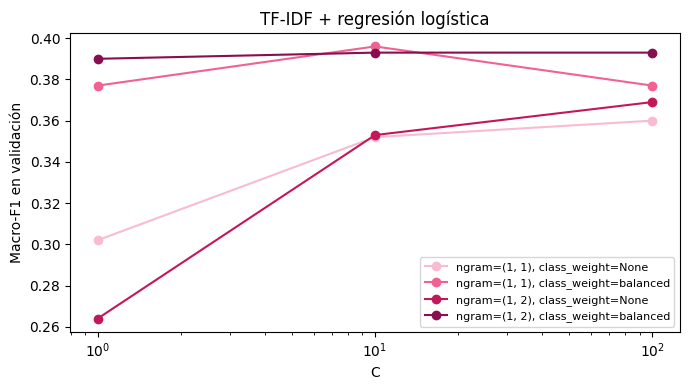

In [8]:
# Macro-F1 en validación según C, para cada combinación
plt.figure(figsize=(7, 4))
colores = ["#f8bbd0", "#f06292", "#c2185b", "#880e4f"]
for color, ((ngram, cw), grupo) in zip(colores, busqueda.groupby(["ngram_range", "class_weight"])):
    plt.plot(grupo["C"], grupo["val macro-F1"], marker="o", color=color, label=f"ngram={ngram}, class_weight={cw}")
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("Macro-F1 en validación")
plt.title("TF-IDF + regresión logística")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "tfidf_logreg_validacion.png", dpi=120)
plt.show()

In [9]:
mejor = busqueda.loc[busqueda["val macro-F1"].idxmax()]

# Si la mejor configuración solo con palabras sueltas está prácticamente empatada con la mejor
# (menos de 0,005 de diferencia, muy por debajo de la incertidumbre de la validación),
# preferimos la más sencilla: vocabulario 6 veces menor y entrenamiento mucho más rápido.
mejor_unigramas = busqueda[busqueda["ngram_range"] == "(1, 1)"].sort_values("val macro-F1").iloc[-1]
if mejor["val macro-F1"] - mejor_unigramas["val macro-F1"] < 0.005:
    mejor = mejor_unigramas

NGRAM = eval(mejor["ngram_range"])
CLASS_WEIGHT = None if mejor["class_weight"] == "None" else mejor["class_weight"]
C = mejor["C"]
print(f"Configuración elegida: ngram_range={NGRAM}, class_weight={CLASS_WEIGHT}, C={C}")
print(f"val macro-F1 = {mejor['val macro-F1']}")

# >>> Esto es lo que hay que pasarle a Lucía F. para su red <<<
print("\nPARAMETROS_TFIDF =", {"min_df": 5, "max_df": 0.5, "sublinear_tf": True, "ngram_range": NGRAM})

Configuración elegida: ngram_range=(1, 1), class_weight=balanced, C=10
val macro-F1 = 0.396

PARAMETROS_TFIDF = {'min_df': 5, 'max_df': 0.5, 'sublinear_tf': True, 'ngram_range': (1, 1)}


**Antes de seguir, comprobar la tabla**: si el mejor `C` es el mayor o el menor de los probados
(1 o 100), el óptimo podría estar fuera de la rejilla. En ese caso, añadir valores más allá
(por ejemplo 1000 o 0.1) y volver a ejecutar.

Con la configuración ya elegida, predecimos validación y test (el test **solo esta vez**),
para nivel 2 y nivel 1.

In [10]:
vectorizador, X_train, X_val, X_test = tfidf[NGRAM]
modelos_finales = {}
for nivel in ["nivel2", "nivel1"]:
    clf = LogisticRegression(C=C, class_weight=CLASS_WEIGHT, max_iter=1000)
    clf.fit(X_train, train[nivel])
    modelos_finales[nivel] = clf
    for nombre, df, X in [("val", val, X_val), ("test", test, X_test)]:
        guardar_predicciones(df, clf.predict(X), "tfidf_logreg", nivel, nombre)
    print(f"{nivel}: val macro-F1 = {f1_score(val[nivel], clf.predict(X_val), average='macro'):.3f}")

nivel2: val macro-F1 = 0.396
nivel1: val macro-F1 = 0.602


## 4. ¿Qué palabras usa el modelo?

Una ventaja de TF-IDF + regresión logística es que se puede interpretar: el modelo tiene un peso por
palabra y por clase. Las palabras con mayor peso son las que más empujan hacia esa clase.

In [11]:
clf = modelos_finales["nivel2"]
palabras = vectorizador.get_feature_names_out()
for clase in ["computer and information sciences", "basic medicine", "earth and related environmental sciences",
              "economics and business", "history and archaeology"]:
    pesos = clf.coef_[list(clf.classes_).index(clase)]
    top = palabras[np.argsort(pesos)[::-1][:10]]
    print(f"{clase}: {', '.join(top)}")

computer and information sciences: software, data, artificial, database, reality, processing, learning, machine, intelligence, virtual
basic medicine: pharmaceutical, antibiotic, immune, discovery, drug, medicinal, medication, patient, epilepsy, neurological
earth and related environmental sciences: climate, change, crystallography, aquatic, disaster, pollution, weather, soil, earthquake, storm
economics and business: productivity, economics, entrepreneurship, labour, smes, online, innovation, employment, macroeconomic, commerce
history and archaeology: history, archaeological, archaeology, modern, medieval, age, century, cultural, published, secular


## 5. Antes de terminar

- Pasar a Lucía F. la línea `PARAMETROS_TFIDF` del apartado 3.
- Copiar al repositorio: `resultados/tfidf_logreg_*`, `figuras/tfidf_logreg_validacion.png` y este
  notebook a `notebooks/02_tfidf_sklearn.ipynb`.
- README, secciones 4.1 (TF-IDF: preprocesado y parámetros) y 5.1 (regresión logística: búsqueda
  de hiperparámetros, configuración elegida y palabras más importantes).